# NBA Draft Value Analysis (2000–2020)
### Who Were the Biggest Steals and Busts?

This notebook analyzes **21 years of NBA draft data** to answer:
- What career value does each draft position *typically* produce?
- Which players massively **outperformed** their draft slot (steals)?
- Which high picks **underperformed** expectations (busts)?
- Which **teams** are the best and worst drafters?
- Can we **predict** career value from draft position?

**Data:** Basketball Reference (scraped)  
**Value metric:** Composite of Win Shares + VORP  
**Models:** Polynomial regression (baseline), Gradient Boosting (improved)

## 0. Setup

In [1]:
import sys, os

# In Google Colab, download the project code first (the notebook alone doesn't include it)
if 'google.colab' in sys.modules and not os.path.exists('../src'):
    !git clone -q https://github.com/Agastya191/nba-draft-analysis.git /content/nba-draft-analysis
    %cd /content/nba-draft-analysis/notebooks

sys.path.insert(0, os.path.abspath('../src'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import warnings
warnings.filterwarnings('ignore')

from scraper    import scrape_all_drafts
from preprocess import clean_and_engineer
from analysis   import run_all_analyses
from model      import run_models
from visualize  import generate_all_figures, set_style

set_style()
print('Setup complete.')

Setup complete.


## 1. Scrape Data

This scrapes Basketball Reference for all NBA drafts 2000–2020.  
**Takes ~5 minutes** due to rate limiting (4s per request, ~21 requests).  
Data is saved to `data/draft_data_raw.csv` — skip scraping if file exists.

In [2]:
RAW_PATH = '../data/draft_data_raw.csv'

# Use the cached file only if it has the Win Shares column (older caches don't)
cached = pd.read_csv(RAW_PATH) if os.path.exists(RAW_PATH) else None
if cached is not None and 'win_shares' in cached.columns:
    print('Loading cached data...')
    raw_df = cached
    print(f'Loaded {len(raw_df)} picks from cache.')
else:
    print('Scraping data from Basketball Reference...')
    raw_df = scrape_all_drafts(start=2000, end=2020, save_path=RAW_PATH)

raw_df.head()

Loading cached data...
Loaded 1249 picks from cache.


,pick,player,team,college,draft_year,years_active,ws_per_48,BPM,VORP
0,1,Kenyon Martin,NJN,Cincinnati,2000,15.0,0.100,0.1,12.1
1,2,Stromile Swift,VAN,LSU,2000,9.0,0.095,-1.6,1.1
2,3,Darius Miles,LAC,NaN,2000,7.0,0.039,-1.0,3.0
3,4,Marcus Fizer,CHI,Iowa State,2000,6.0,0.022,-3.7,-2.6
4,5,Mike Miller,ORL,Florida,2000,17.0,0.105,0.8,19.8


## 2. Clean & Engineer Features

In [3]:
df = clean_and_engineer(raw_df)
print(f'\nDataset: {len(df)} picks across {df["draft_year"].nunique()} draft years')
df[['player','draft_year','pick','pick_tier','win_shares','VORP','value_score','value_over_expected']].head(10)

Processed 1249 draft picks.
  Steals: 125 | Busts: 130

Dataset: 1249 picks across 21 draft years


,player,draft_year,pick,pick_tier,VORP,value_score,value_over_expected
0,Kenyon Martin,2000,1,Top 5,12.1,36.3,-11.1
1,Stromile Swift,2000,2,Top 5,1.1,3.3,-4.2
2,Darius Miles,2000,3,Top 5,3.0,9.0,-33.3
3,Marcus Fizer,2000,4,Top 5,-2.6,-7.8,-19.5
4,Mike Miller,2000,5,Top 5,19.8,59.4,29.1
5,DerMarr Johnson,2000,6,Lottery (6-10),0.6,1.8,-11.1
6,Chris Mihm,2000,7,Lottery (6-10),-4.3,-12.9,-28.8
7,Jamal Crawford,2000,8,Lottery (6-10),18.4,55.2,46.2
8,Joel Przybilla,2000,9,Lottery (6-10),0.8,2.4,-8.7
9,Keyon Dooling,2000,10,Lottery (6-10),-0.2,-0.6,-7.8


In [4]:
# Distribution of value scores
print('Value Score Distribution:')
df['value_score'].describe().round(2)

Value Score Distribution:


count    1249.00
mean       12.49
std        33.40
min       -19.50
25%        -0.90
50%         0.00
75%        12.30
max       478.20
Name: value_score, dtype: float64

## 3. Run All Analyses

In [5]:
results       = run_all_analyses(df)
model_results = run_models(df)

Running analyses...
  All analyses complete.
Training models...
  Baseline model  — CV MAE: 5.39 WS | R²: 0.122
  Improved model  — CV MAE: 16.78 VS | R²: 0.037
  Team efficiency — 34 teams ranked


## 4. Draft Value Curve

In [6]:
print('Pick Value Curve (median WS by pick):')
results['pick_value_curve'].head(15)

Pick Value Curve (median WS by pick):


,pick,median_ws,median_value,n
0,1,15.8,47.4,21
1,2,2.5,7.5,21
2,3,14.1,42.3,21
3,4,3.9,11.7,21
4,5,10.1,30.3,21
5,6,4.3,12.9,21
6,7,5.3,15.9,21
7,8,3.0,9.0,21
8,9,3.7,11.1,21
9,10,2.4,7.2,21


In [7]:
print(f'Baseline model (pick → WS): MAE={model_results["baseline"]["cv_mae"]} WS, R²={model_results["baseline"]["cv_r2"]}')
print(f'Improved model (pick+era → value): MAE={model_results["improved"]["cv_mae"]}, R²={model_results["improved"]["cv_r2"]}')
print(f'\nFeature Importances:')
print(model_results['improved']['feature_importance'])

Baseline model (pick → WS): MAE=5.39 WS, R²=0.122
Improved model (pick+era → value): MAE=16.78, R²=0.037

Feature Importances:
draft_year    0.536667
pick          0.460666
round         0.002666
dtype: float64


## 5. Greatest Steals

In [8]:
print('TOP 20 DRAFT STEALS (2000-2020)')
print('Players who most outperformed their draft position expected value')
print('='*70)
results['top_steals'][['player','draft_year','pick','win_shares','VORP','value_over_expected']]

TOP 20 DRAFT STEALS (2000-2020)
Players who most outperformed their draft position expected value


,player,draft_year,pick,VORP,VORP,VORP,VORP,value_over_expected
0,LeBron James,2003,1,159.4,159.4,159.4,159.4,430.8
1,Chris Paul,2005,4,98.8,98.8,98.8,98.8,284.7
2,Kevin Durant,2007,2,92.2,92.2,92.2,92.2,269.1
3,Nikola JokiÄ,2014,41,82.5,82.5,82.5,82.5,247.8
4,James Harden,2009,3,87.9,87.9,87.9,87.9,221.4
5,Stephen Curry,2009,7,77.2,77.2,77.2,77.2,215.7
6,Giannis Antetokounmpo,2013,15,65.5,65.5,65.5,65.5,195.3
7,Russell Westbrook,2008,4,59.1,59.1,59.1,59.1,165.6
8,Kawhi Leonard,2011,15,55.2,55.2,55.2,55.2,164.4
9,Dwyane Wade,2003,5,62.8,62.8,62.8,62.8,158.1


## 6. Biggest Busts

In [9]:
print('TOP 20 DRAFT BUSTS (2000-2020, Picks 1-20 only)')
print('High picks who most underperformed their expected value')
print('='*70)
results['top_busts'][['player','draft_year','pick','win_shares','VORP','value_over_expected']]

TOP 20 DRAFT BUSTS (2000-2020, Picks 1-20 only)
High picks who most underperformed their expected value


,player,draft_year,pick,VORP,VORP,VORP,VORP,value_over_expected
0,Anthony Bennett,2013,1,-1.3,-1.3,-1.3,-1.3,-51.3
1,Kwame Brown,2001,1,-1.3,-1.3,-1.3,-1.3,-51.3
2,Adam Morrison,2006,3,-2.4,-2.4,-2.4,-2.4,-49.5
3,Greg Oden,2007,1,0.8,0.8,0.8,0.8,-45.0
4,Markelle Fultz,2017,1,1.1,1.1,1.1,1.1,-44.1
5,Andrea Bargnani,2006,1,1.5,1.5,1.5,1.5,-42.9
6,Jahlil Okafor,2015,3,0.0,0.0,0.0,0.0,-42.3
7,RJ Barrett,2019,3,1.8,1.8,1.8,1.8,-36.9
8,Nikoloz Tskitishvili,2002,5,-2.0,-2.0,-2.0,-2.0,-36.3
9,Thomas Robinson,2012,5,-1.6,-1.6,-1.6,-1.6,-35.1


## 7. Best Second-Round Picks

In [10]:
print('BEST SECOND ROUND PICKS (2000-2020)')
results['second_round_steals'][['player','draft_year','pick','win_shares','VORP']]

BEST SECOND ROUND PICKS (2000-2020)


,player,draft_year,pick,VORP,VORP
0,Nikola JokiÄ,2014,41,82.5,82.5
1,Marc Gasol,2007,48,36.5,36.5
2,Paul Millsap,2006,47,29.9,29.9
3,Draymond Green,2012,35,27.9,27.9
4,Lou Williams,2005,45,23.2,23.2
5,Carlos Boozer,2002,35,23.1,23.1
6,Gilbert Arenas,2001,31,22.3,22.3
7,DeAndre Jordan,2008,35,22.2,22.2
8,Trevor Ariza,2004,43,21.8,21.8
9,Michael Redd,2000,43,21.4,21.4


## 8. Value by Pick Tier

In [11]:
results['value_by_tier'].style \
    .background_gradient(cmap='Blues', subset=['median_ws']) \
    .background_gradient(cmap='Reds',  subset=['pct_busts'])

,pick_tier,n_picks,median_ws,median_vorp,median_value,pct_busts,pct_steals
0,Top 5,105,10.300000,10.300000,30.900000,34.300000,24.800000
1,Lottery (6-10),105,3.700000,3.700000,11.100000,38.100000,21.900000
2,Lottery (11-14),84,2.050000,2.050000,6.150000,21.400000,16.700000
3,Late 1st,334,0.200000,0.200000,0.600000,9.000000,11.700000
4,Early 2nd,315,0.000000,0.000000,0.000000,1.600000,5.400000
5,Late 2nd,306,0.000000,0.000000,0.000000,0.300000,2.000000


## 9. Team Drafting Efficiency

In [12]:
print('BEST DRAFTING TEAMS (min 10 picks, 2000-2020)')
model_results['teams'][['team','total_picks','avg_value_over_exp','total_value_over_exp','best_pick']].head(15)

BEST DRAFTING TEAMS (min 10 picks, 2000-2020)


,team,total_picks,avg_value_over_exp,total_value_over_exp,best_pick
0,NOH,14,39.77,556.8,Chris Paul
1,SEA,28,17.41,487.5,Kevin Durant
2,CLE,35,16.78,587.4,LeBron James
3,DEN,36,16.58,597.0,Nikola JokiÄ
4,OKC,21,15.84,332.7,James Harden
5,GSW,36,14.21,511.5,Stephen Curry
6,MEM,34,13.41,456.0,Kyle Lowry
7,HOU,34,12.17,413.7,Nicolas Batum
8,IND,35,11.93,417.6,Kawhi Leonard
9,MIA,31,10.99,340.8,Dwyane Wade


## 10. Generate All Figures

Generating figures...
  Saved: /Users/agmunnangi/Downloads/nba-draft-analysis/src/../outputs/01_pick_value_curve.png
  Saved: /Users/agmunnangi/Downloads/nba-draft-analysis/src/../outputs/02_top_steals.png
  Saved: /Users/agmunnangi/Downloads/nba-draft-analysis/src/../outputs/03_top_busts.png
  Saved: /Users/agmunnangi/Downloads/nba-draft-analysis/src/../outputs/04_value_by_tier.png
  Saved: /Users/agmunnangi/Downloads/nba-draft-analysis/src/../outputs/06_second_round_steals.png
  Saved: /Users/agmunnangi/Downloads/nba-draft-analysis/src/../outputs/07_era_comparison.png
  Saved: /Users/agmunnangi/Downloads/nba-draft-analysis/src/../outputs/05_team_efficiency.png
  7 figures saved.


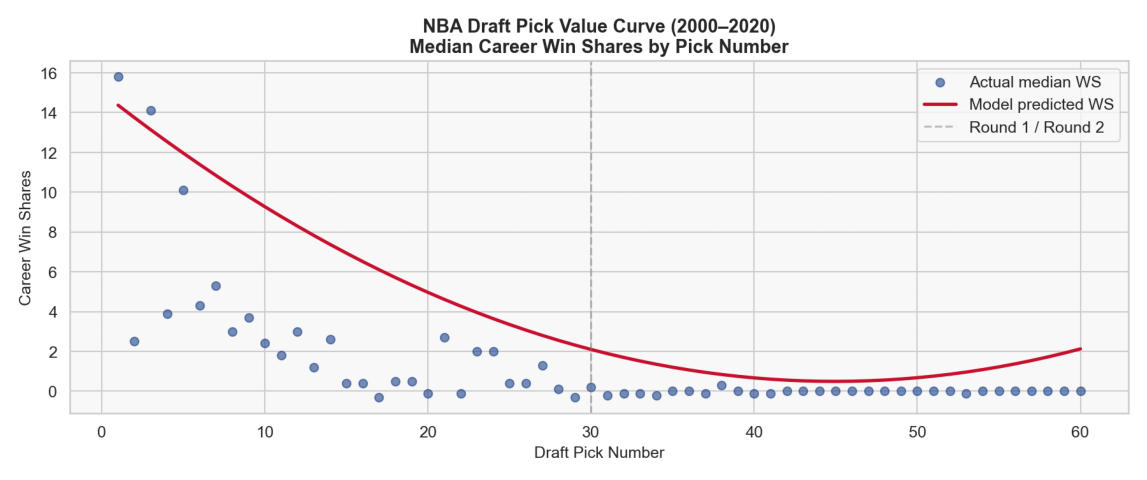

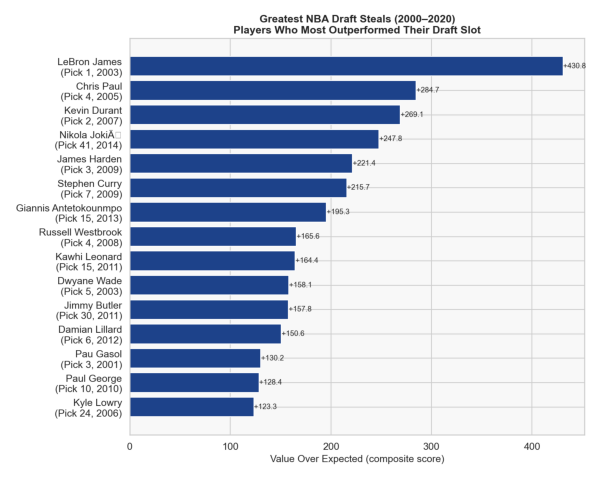

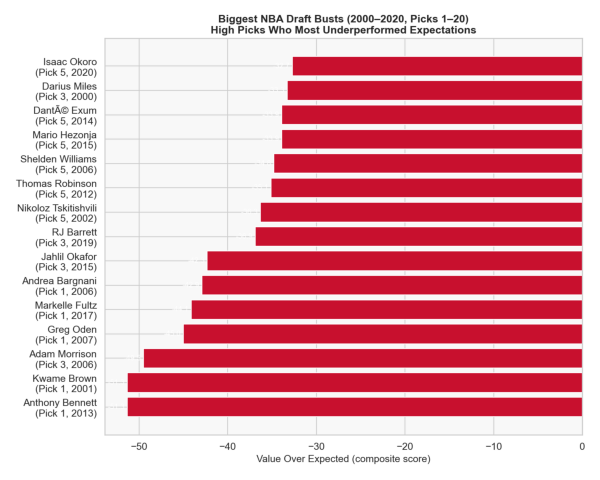

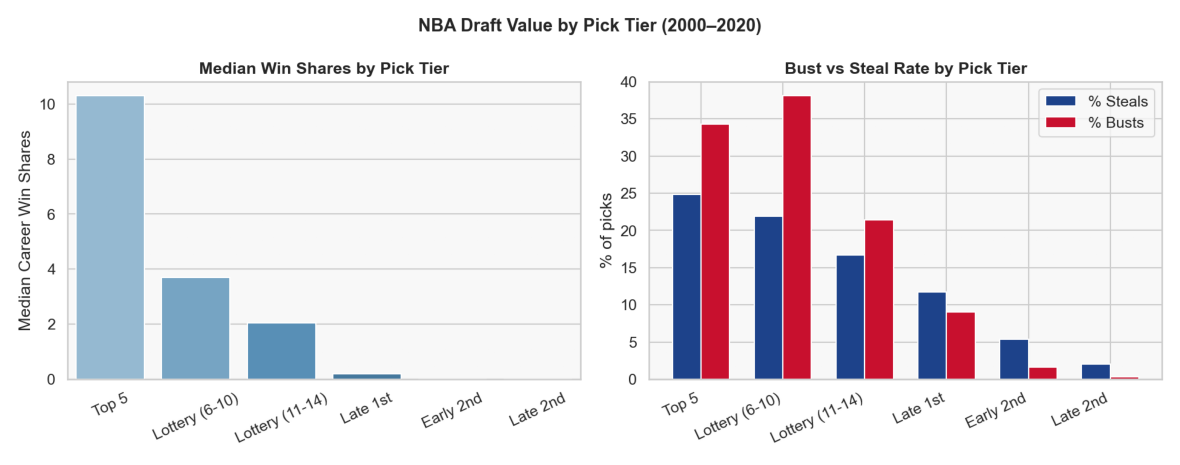

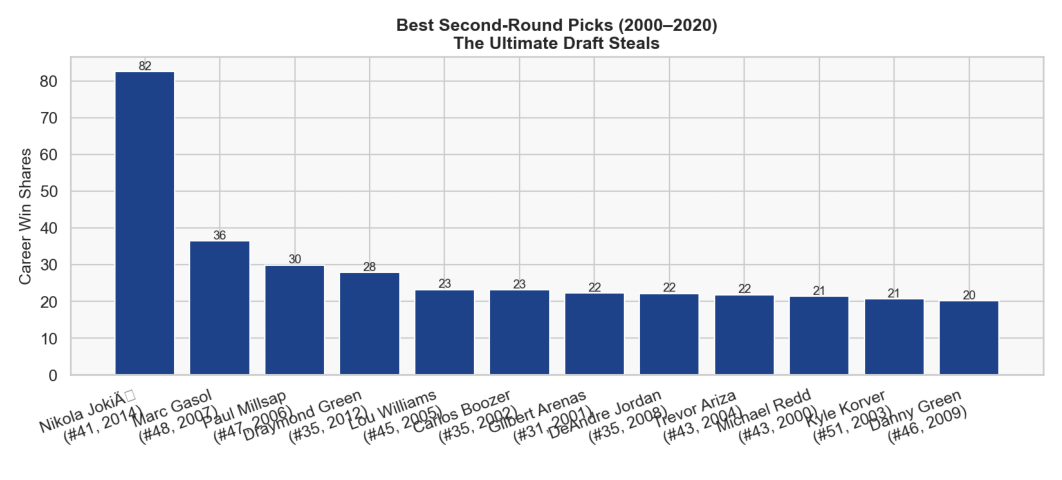

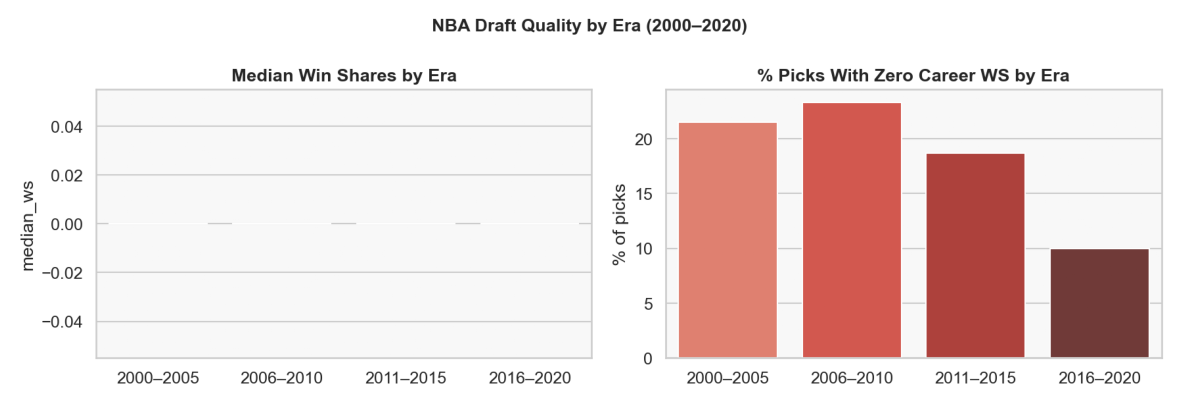

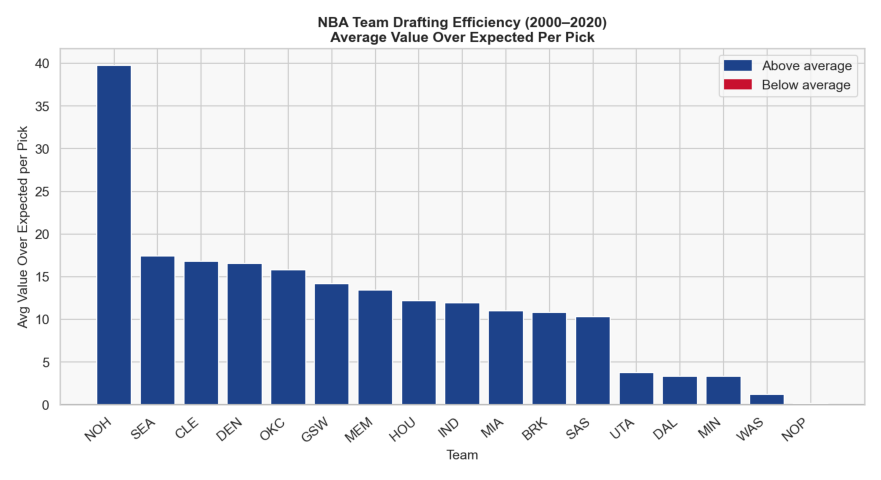

In [13]:
figure_paths = generate_all_figures(results, model_results)

for path in figure_paths:
    img = mpimg.imread(path)
    plt.figure(figsize=(12, 5))
    plt.imshow(img)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

## 11. Key Findings

A summary of the results from the latest full run is in the project README.